# Pipeline Dataset

Pengambilan dataset terinspirasi dari VERITE, namun dengan berita berbahasa Indonesia

## **0. Parameter & Utilities**

| Variabel  | Nilai                   | Keterangan                                                                                                                                    |
| --------- | ----------------------- | --------------------------------------------------------------------------------------------------------------------------------------------- |
| PAGES     | 1 sampai 257, langkah 8 | Halaman tag yang akan diperiksa. Jarak 8 halaman digunakan agar pencarian mencakup rentang waktu yang lebih luas, bukan hanya berita terbaru. |
| LIMIT     | 5000                    | Batas maksimal jumlah URL yang akan dikumpulkan.                                                                                              |
| MONTH_CAP | 0,15                    | Setiap bulan dibatasi maksimal 15% dari total kuota agar data tidak didominasi oleh satu bulan tertentu.                                      |
| SEED      | 42                      | Angka awal untuk pengacakan agar proses pengambilan sampel dapat menghasilkan hasil yang sama ketika diulang.                                 |
| MODEL     | deepseek-v4.1-flash     | Model AI yang digunakan untuk menilai kesesuaian konten dan menulis ulang caption MC.                                                         |
| BATCH     | 8                       | Jumlah caption yang diproses sekaligus dalam satu permintaan ke model AI.                                                                     |

In [11]:
from pathlib import Path

import base64, datetime, difflib, hashlib
import io, html as ihtml, json, os, random, re, time
import urllib.error, urllib.request, uuid

from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

from PIL import Image

try:
    from tqdm.auto import tqdm
except ImportError:
    class tqdm:
        def __init__(self, iterable=None, total=None, desc=None, unit=None, disable=False):
            self.iterable = iterable if iterable is not None else []

        def __iter__(self):
            return iter(self.iterable)

        def update(self, n=1):
            pass

        def set_postfix(self, **kw):
            pass

        def close(self):
            pass


def repo_root(start: Path | None = None) -> Path:
    p = (start or Path.cwd()).resolve()
    while p != p.parent:
        if (p / ".git").exists():
            return p
        p = p.parent
    return (start or Path.cwd()).resolve()


ROOT = repo_root()
OUT = ROOT / "data"
OUT.mkdir(parents=True, exist_ok=True)


def load_env(path: Path):
    if not path.exists():
        return
    for line in path.read_text().splitlines():
        if "=" in line and not line.strip().startswith("#"):
            k, v = line.split("=", 1)
            os.environ.setdefault(k.strip(), v.strip())


load_env(ROOT / ".env")


LIMIT = 5000
PAGES = list(range(1, 258, 8))
MONTH_CAP = 0.15

WORKERS = 8
SEED = 727
VERBOSE = True
RECOLLECT = False

MODEL = "deepseek-v4.1-flash"
API_URL = "https://opencode.ai/inference/go/openai/v1/chat/completions"
BATCH = 8
IMAGE_LIMIT = 0        # 0 = unduh semua gambar

UA = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) Chrome/120 Safari/537.36"}

rng_ooc = random.Random(SEED + 1)


def jumlah_baris(path: Path) -> int:
    return sum(1 for _ in open(path)) if path.exists() else 0


def label_data(path: Path) -> str:
    try:
        return str(path.relative_to(OUT))
    except ValueError:
        return path.name


def write_json(path: Path, obj):
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=0, ensure_ascii=False))
    os.replace(tmp, path)
    isi = f"{len(obj)} entri" if isinstance(obj, list) else "1 objek"
    print(f"tulis: {label_data(path)} ({isi})")


def write_jsonl(path: Path, rows):
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    os.replace(tmp, path)
    print(f"tulis: {label_data(path)} ({len(rows)} baris)")


def read_jsonl(path: Path):
    if not path.exists():
        return []
    return [json.loads(l) for l in open(path) if l.strip()]


def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


print("root:", ROOT)
print("keluaran:", OUT)
print("\nparameter")
print("  limit:", LIMIT) 
print("  model:", MODEL)
print("  recollect:", RECOLLECT)
print("  workers:", WORKERS)
print("  seed:", SEED)


root: /home/prayudahlah/projects/college/ml/image-text-verification
keluaran: /home/prayudahlah/projects/college/ml/image-text-verification/data

parameter
  limit: 5000
  model: deepseek-v4.1-flash
  recollect: False
  workers: 8
  seed: 727


## **1. Utilitas HTTP**

In [12]:
def get(url: str, retries: int = 2, timeout: int = 30) -> str:
    for i in range(retries):
        try:
            req = urllib.request.Request(url, headers=UA)
            with urllib.request.urlopen(req, timeout=timeout) as r:
                return r.read().decode("utf8", "ignore")
        except Exception:
            if i == retries - 1:
                raise
            time.sleep(1)

# Contoh, ambil 80 karakter pertama
print(get("https://www.kompas.com/tag/banjir?page=1")[:80])

<!DOCTYPE html>
<html lang="id">
<head>
       
<!-- Google Tag Manager -->
<scr


## **2. Pengumpulan URL**

Hasil disimpan ke `data/01_urls.json` dan dipakai ulang pada run berikutnya.

| Keputusan       | Nilai                                       | Keterangan                                                                                                                 |
| --------------- | ------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------- |
| Sumber          | Halaman tag `kompas.com/tag/<topik>?page=N` | Menggunakan halaman berdasarkan topik agar pencarian berita lebih terarah dibandingkan halaman utama channel.              |
| Topik           | 54 tag dalam 9 kelompok                     | Mencakup berbagai kategori, seperti bencana, kriminal, politik, ekonomi, sosial, gaya hidup, lingkungan, dan wilayah kota. |
| Halaman         | 1 sampai 257, langkah 8                     | Mengambil halaman dengan jarak 8 agar pencarian mencakup rentang waktu yang lebih luas.                                    |
| Kombinasi       | 54 × 33 halaman                             | Setiap tag diperiksa pada seluruh nomor halaman yang telah ditentukan.                                                     |
| Batas per bulan | 15% dari kuota                              | Membatasi jumlah artikel dari setiap bulan agar data tidak didominasi oleh periode tertentu.                               |
| Pola URL        | `/read/tahun/bulan/tanggal/slug`            | Memastikan tautan yang dikumpulkan mengarah ke halaman artikel berita.                                                     |
| Deduplikasi     | `seen` (set)                                | Mencegah URL yang sama dimasukkan lebih dari satu kali meskipun ditemukan pada beberapa tag.                               |
| Cache           | `data/01_urls.json`                            | Menyimpan daftar URL agar dapat digunakan kembali pada proses berikutnya tanpa mengulang pengumpulan.                      |

In [13]:
ARTICLE = re.compile(r'href="(https://[a-z]+\.kompas\.com/read/\d{4}/\d{2}/\d{2}/[^"]+)"')


def add_urls(urls: list[str], seen: set[str], url: str) -> int:
    try:
        page = get(url)
    except Exception:
        return 0
    added = 0
    for u in ARTICLE.findall(page):
        if u not in seen:
            seen.add(u)
            urls.append(u)
            added += 1
    return added


TAGS = [
    # bencana dan cuaca
    "banjir", "banjir-bandang", "longsor", "tanah-longsor", "gempa", "gempa-bumi",
    "kebakaran", "kebakaran-hutan", "bencana", "cuaca",

    # kriminal dan hukum
    "kriminal", "kriminalitas", "korupsi", "hukum", "pengadilan",
    "kecelakaan", "kecelakaan-lalu-lintas",

    # politik dan pemerintahan
    "politik", "pemilu", "pemerintahan", "demo",

    # ekonomi dan pembangunan
    "ekonomi", "perdagangan", "pangan", "pertanian", "perikanan",
    "energi", "infrastruktur", "transportasi",

    # sosial
    "kesehatan", "kesehatan-masyarakat", "pendidikan", "kesejahteraan",

    # gaya hidup dan teknologi
    "olahraga", "teknologi", "otomotif", "travel", "gaya-hidup",
    "properti", "internasional",

    # lingkungan
    "lingkungan", "lingkungan-hidup",

    # kota
    "jakarta", "surabaya", "bandung", "semarang", "medan", "makassar",
    "palembang", "yogyakarta", "malang", "denpasar",
    
    # lain-lain
    "viral", "hoaks",
]


def month_of(url: str) -> str:
    m = re.search(r"/read/(\d{4})/(\d{2})/", url)
    return f"{m.group(1)}-{m.group(2)}" if m else "?"


def collect_pages(pages: list[int]) -> list[str]:
    urls, seen = [], set()
    combos = [(tag, p) for tag in TAGS for p in pages]
    bar = tqdm(combos, desc="URL", unit="halaman", disable=not VERBOSE)
    for tag, page in bar:
        add_urls(urls, seen, f"https://www.kompas.com/tag/{tag}?page={page}")
        bar.set_postfix(url=len(urls))
    return urls


def cap_by_month(urls: list[str], limit: int, ratio: float = MONTH_CAP) -> list[str]:
    rng = random.Random(SEED)
    by = defaultdict(list)
    for u in urls:
        by[month_of(u)].append(u)
    cap = max(1, int(limit * ratio))
    picked = []
    for m in sorted(by):
        lst = by[m]
        rng.shuffle(lst)
        picked += lst[:cap]
    if len(picked) > limit:
        rng.shuffle(picked)
        picked = picked[:limit]
    return picked


In [14]:
URLS = OUT / "01_urls.json"
if URLS.exists() and not RECOLLECT:
    urls = json.loads(URLS.read_text())[:LIMIT]
    print(f"memakai daftar tersimpan: {len(urls)} URL")
else:
    t0 = time.time()
    kandidat = collect_pages(PAGES)
    urls = cap_by_month(kandidat, LIMIT)
    write_json(URLS, urls)
    print(f"kandidat: {len(kandidat)} | dipakai: {len(urls)} | {time.time()-t0:.0f} detik")
print(urls[0])

memakai daftar tersimpan: 5000 URL
https://agri.kompas.com/read/2022/11/16/103200184/kenali-prinsip-kerja-dan-cara-mengoperasikan-mesin-combine-harvester


## 3. Parsing artikel

| Keputusan            | Nilai                                                     | Keterangan                                                                         |
| -------------------- | --------------------------------------------------------- | ---------------------------------------------------------------------------------- |
| Field yang diambil   | Judul, gambar, caption, channel→category                  | Empat field utama untuk membentuk pasangan data.                                   |
| Sumber gambar        | Metadata `og:image`                                       | Mengambil gambar utama yang digunakan saat tautan dibagikan.                       |
| Sumber caption       | `photo__caption` dalam blok `cover-photo`                 | Memastikan caption berasal dari blok foto yang relevan.                            |
| Validasi pasangan    | Kesamaan path `/data/photo/...`                           | Memeriksa kesamaan identitas aset gambar meskipun URL crop atau watermark berbeda. |
| Pasangan tidak valid | Caption dikosongkan                                       | Termasuk ketika gambar pembanding tidak ditemukan atau blok foto tidak utuh.       |
| Batas blok foto      | Penanda `photo carousel`                                  | Digunakan untuk menentukan batas ekstraksi blok foto.                              |
| Pembersihan teks     | Penghapusan tag, decoding entitas HTML, normalisasi spasi | Menghasilkan teks biasa yang bersih.                                               |
| Channel              | Subdomain URL                                             | Disimpan dalam kolom `category`.                                                   |
| Halaman gagal        | Dilewati                                                  | Kegagalan satu halaman tidak menghentikan proses.                                  |
| Pemrosesan paralel   | 8 workers                                                 | Mempercepat ekstraksi melalui beberapa thread.                                     |
| Idempotensi          | Pengecekan URL pada `02_articles_raw.jsonl`               | Mencegah pemrosesan ulang artikel yang sudah tersimpan.                            |
| Penulisan data       | Mode append, satu artikel per baris                       | Memungkinkan proses dilanjutkan tanpa menghapus hasil sebelumnya.                  |

In [15]:
def plain(s: str) -> str:
    return re.sub(r"\s+", " ", ihtml.unescape(re.sub(r"<[^>]+>", " ", s))).strip()


# greedy [^>]+ sengaja dipakai supaya "src" menang atas "data-src"
FOTO = re.compile(r'<img[^>]+src="([^"]+)"')
CAPTION = re.compile(r'<div class="photo__caption[^"]*"[^>]*>(.*?)</div>', re.S)
FOTO_PATH = re.compile(r"/data/photo/[\w/.-]+")


def blok_foto(page: str):
    """Potongan HTML blok foto utama, beserta penanda apakah bloknya utuh."""
    i = page.find('<div class="cover-photo')
    if i < 0:
        return "", False
    j = page.find("<!-- photo carousel -->", i)
    if j < 0:
        return "", False
    return page[i:j], True


def parse(url: str) -> dict:
    page = get(url)
    blok, utuh = blok_foto(page)
    img = FOTO.search(blok)
    cap = CAPTION.search(blok)
    og = re.search(r'property="og:image" content="([^"]+)"', page)
    title = re.search(r"<h1[^>]*>(.*?)</h1>", page, re.S)
    cat = re.search(r"//([a-z]+)\.kompas\.com/", url)

    image = og.group(1) if og else (img.group(1) if img else "")
    caption = plain(cap.group(1)) if (cap and utuh) else ""

    # lebih baik gugur daripada menebak pasangan yang tidak terbukti
    if caption:
        if og and not img:
            caption = ""
        elif og and img:
            k_og = FOTO_PATH.findall(og.group(1))
            k_img = FOTO_PATH.findall(img.group(1))
            if not (k_og and k_img and k_og[-1] == k_img[-1]):
                caption = ""

    return {
        "url": url,
        "title": plain(title.group(1)) if title else "",
        "image": image,
        "caption": caption,
        "category": cat.group(1) if cat else "",
    }


def safe(u: str):
    try:
        return parse(u)
    except Exception:
        return None


In [16]:
RAW = OUT / "02_articles_raw.jsonl"
done = {a["url"] for a in read_jsonl(RAW)}
todo = [u for u in urls if u not in done]
print(f"sudah ada {len(done)} | sisa {len(todo)}")

t0 = time.time()
if not todo:
    print("tidak ada halaman baru")
else:
    with open(RAW, "a") as f, ThreadPoolExecutor(max_workers=WORKERS) as ex:
        it = tqdm(ex.map(safe, todo), total=len(todo), desc="parsing",
                  unit="artikel", disable=not VERBOSE)
        for a in it:
            if a is not None:
                f.write(json.dumps(a, ensure_ascii=False) + "\n")
    print(f"selesai parsing | {time.time()-t0:.0f} detik")

sudah ada 8848 | sisa 0
tidak ada halaman baru


## 4. Penyaringan dan deduplikasi

1. Menghapus URL artikel duplikat.
2. Menyaring artikel berdasarkan kelengkapan dan kualitas field.
3. Menghapus artikel dengan foto duplikat.
4. Memisahkan caption berbahasa Inggris dengan heuristic language filtering.
5. Menyimpan dataset hasil penyaringan dan data yang dipisahkan.

In [17]:
SKIP_IMAGE = re.compile(r"(logo|default|placeholder|avatar|icon)", re.I)

EN = set("the and of to in is was were be been for with on at by from as that this "
         "it its has have had will would can could not but or an are we they he she "
         "his her their our you your".split())
ID = set("yang dan di ke dari untuk dengan pada itu ini tidak akan juga karena "
         "setelah dalam oleh sebagai saat sudah bisa lebih kata para bagi serta "
         "atau ada telah ia mereka kita kami dia".split())


def photo_key(url: str) -> str:
    """Kunci foto yang stabil terhadap perbedaan crop dan parameter filter."""
    m = re.search(r"/data/photo/[\w/.-]+", url)
    return m.group(0) if m else url


def bahasa_inggris(caption: str) -> bool:
    """True kalau caption didominasi kata fungsi bahasa Inggris."""
    kata = re.findall(r"[a-zA-Z]+", (caption or "").lower())
    if len(kata) < 4:
        return False
    en = sum(1 for k in kata if k in EN)
    idn = sum(1 for k in kata if k in ID)
    return en >= 2 and en / (en + idn + 1e-9) >= 0.6


# 1. buang URL artikel yang ganda
raw, seen_url = [], set()
for a in tqdm(read_jsonl(RAW), desc="filter", unit="artikel", disable=not VERBOSE):
    if a["url"] in seen_url:
        continue
    seen_url.add(a["url"])
    raw.append(a)

# 2. saring artikel berdasarkan kelengkapan dan kualitas field
arts, reject = [], Counter()
for a in raw:
    if not a["image"]:
        reject["tanpa gambar"] += 1
    elif SKIP_IMAGE.search(a["image"]):
        reject["gambar logo atau placeholder"] += 1
    elif len(a["caption"].split()) < 6:
        reject["caption terlalu pendek atau kosong"] += 1
    elif len(a["title"].split()) < 4:
        reject["judul terlalu pendek"] += 1
    else:
        arts.append(a)

# 3. buang artikel yang fotonya sudah dipakai artikel lain
seen, uniq = set(), []
for a in arts:
    key = photo_key(a["image"])
    if key in seen:
        reject["foto duplikat"] += 1
        continue
    seen.add(key)
    uniq.append(a)


# 4. pisahkan caption berbahasa Inggris
asing = [a for a in uniq if bahasa_inggris(a["caption"])]
uniq = [a for a in uniq if not bahasa_inggris(a["caption"])]
reject["caption bahasa Inggris"] += len(asing)

# 5. simpan hasil penyaringan dan data yang dipisahkan
print(f"lolos filter: {len(uniq)}")
for k, v in reject.most_common():
    print(f"  {k}: {v}")
print("kategori penyumbang caption Inggris terbanyak:", Counter(a["category"] for a in asing).most_common(3))
write_jsonl(OUT / "03_articles.jsonl", uniq)
write_jsonl(OUT / "03b_articles_en.jsonl", asing)


filter: 100%|██████████| 8848/8848 [00:00<00:00, 972949.21artikel/s]


lolos filter: 6308
  foto duplikat: 1120
  caption terlalu pendek atau kosong: 1092
  caption bahasa Inggris: 316
  tanpa gambar: 8
  judul terlalu pendek: 4
kategori penyumbang caption Inggris terbanyak: [('go', 304), ('lifestyle', 4), ('travel', 3)]
tulis: 03_articles.jsonl (6308 baris)
tulis: 03b_articles_en.jsonl (316 baris)


## 5. Pasangan true dan out-of-context

Setiap artikel menghasilkan satu pasangan `true` yang terdiri dari gambar dan caption aslinya. Pasangan `out-of-context` dibentuk dengan memasangkan caption suatu artikel dengan gambar dari artikel lain. Pemilihan gambar `out-of-context` diprioritaskan dari channel yang sama, kemudian diperluas ke seluruh dataset apabila tidak tersedia kandidat. Pemilihan dilakukan secara acak menggunakan random generator yang telah ditentukan.

In [18]:
# Pasangan positif: gambar dan caption dari artikel yang sama
pairs = [
    {
        "label": "true",
        "image": a["image"],
        "caption": a["caption"],
        "source": a["url"],
        "category": a["category"]
    }
    for a in uniq
]


# Mengelompokkan artikel berdasarkan channel
by_cat = defaultdict(list)

for a in uniq:
    by_cat[a["category"]].append(a)


# Pasangan negatif: caption asli dengan gambar artikel lain
for a in tqdm(
    uniq,
    desc="out-of-context",
    unit="artikel",
    disable=not VERBOSE
):
    # Memprioritaskan gambar dari artikel lain dalam channel yang sama
    pool = [
        b for b in by_cat[a["category"]]
        if b["url"] != a["url"] and b["image"] != a["image"]
    ]

    # Jika tidak tersedia, gunakan kandidat dari seluruh channel
    if not pool:
        pool = [
            b for b in uniq
            if b["url"] != a["url"] and b["image"] != a["image"]
        ]

    # Memilih kandidat secara acak dan membentuk pasangan negatif
    if pool:
        b = rng_ooc.choice(pool)

        pairs.append({
            "label": "out-of-context",
            "image": b["image"],
            "caption": a["caption"],
            "source": a["url"],
            "category": a["category"]
        })


# Menampilkan jumlah pasangan berdasarkan label
print(
    "true:", sum(1 for p in pairs if p["label"] == "true"),
    "| out-of-context:",
    sum(1 for p in pairs if p["label"] == "out-of-context")
)

out-of-context:   0%|          | 0/6308 [00:00<?, ?artikel/s]

out-of-context: 100%|██████████| 6308/6308 [00:01<00:00, 3283.14artikel/s]

true: 6308 | out-of-context: 6308


## 6. Konstruksi miscaptioned

1. Deteksi entitas secara pencocokan heuristic dari daftar entitas
2. Manipulasi entitas dengan kategori yang sama oleh LLM
3. Validasi caption

In [23]:
TERLIHAT = {
    "bencana": ["banjir", "kebakaran", "tanah longsor", "longsor", "gempa bumi",
                "gempa", "kekeringan", "erupsi", "angin puting beliung"],
    "kendaraan": ["sepeda motor", "motor", "mobil", "truk", "bus", "kereta api",
                  "kapal", "sepeda", "pesawat"],
    "bangunan": ["rumah", "sekolah", "pasar", "kantor", "jembatan", "masjid", "gereja",
                 "gudang", "toko", "terminal", "stasiun", "bandara", "pelabuhan",
                 "gedung", "jalan", "lapangan", "taman", "tenda", "posko", "dermaga"],
    "orang": ["polisi", "tentara", "petugas", "relawan", "warga", "siswa", "guru",
              "pedagang", "nelayan", "petani", "petugas pemadam kebakaran"],
    "alam": ["sawah", "ladang", "hutan", "pantai", "sungai", "gunung", "danau", "perahu"],
}

def find_entity(caption: str):
    for kat, words in TERLIHAT.items():
        for w in words:
            m = re.search(rf"\b{re.escape(w)}\b", caption, flags=re.I)
            if m and not re.match(r"\s+[A-Z]", caption[m.end():m.end() + 2]):
                return w, kat
    return None, None

SYS = (
    "Kamu editor caption berita berbahasa Indonesia. Pada setiap baris ada TARGET, "
    "yaitu entitas yang harus diganti, dan KATEGORI, yaitu jenis penggantinya. "
    "Ganti TARGET dengan entitas lain dari KATEGORI yang sama, sehingga caption tidak "
    "lagi cocok dengan fotonya, tetapi kalimatnya tetap wajar dan panjangnya mirip. "
    "Pilih pengganti yang spesifik dan bervariasi. Dilarang mengubah nama orang, nama "
    "tempat, nama lembaga, tanggal, angka, dan teks dalam tanda kurung. Dilarang "
    "menambah atau menghapus informasi lain. Balas HANYA dengan JSON: "
    "{\"items\":[{\"i\":0,\"caption\":\"...\"}]} tanpa penjelasan."
)

NUM = re.compile(r"\d")

def name_positions(tokens):
    marks = [bool(w[:1].isupper()) for w in tokens]
    out, i = set(), 0
    while i < len(tokens):
        if marks[i]:
            j = i
            while j + 1 < len(tokens) and marks[j + 1]:
                j += 1
            if j > i:
                out.update(range(i, j + 1))
            i = j + 1
        else:
            i += 1
    return out

def check_edits(orig: str, new: str):
    # Memastikan caption baru tidak kosong atau terlalu pendek
    if not new or len(new) < 20:
        return False, "kosong atau terlalu pendek", []

    a, b = orig.split(), new.split()

    # Memastikan panjang caption baru tidak menyimpang lebih dari 15–25%
    if not (0.85 <= len(b) / max(1, len(a)) <= 1.25):
        return False, "panjang menyimpang", []

    # Membandingkan perubahan token antara caption asli dan hasil manipulasi
    sm = difflib.SequenceMatcher(None, a, b)
    names = name_positions(a)
    changed = []

    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        if tag == "equal":
            continue

        old, rep = a[i1:i2], b[j1:j2]

        # Memastikan perubahan tidak melibatkan angka
        if any(NUM.search(w) for w in old + rep):
            return False, "mengubah angka", old + rep

        # Memastikan perubahan tidak melibatkan teks dalam tanda kurung
        if any(w.startswith("(") or w.endswith(")") for w in old + rep):
            return False, "mengubah teks kurung", old + rep

        # Memastikan perubahan tidak melibatkan nama diri yang terdeteksi
        if any(k in names for k in range(i1, i2)):
            return False, "mengubah nama diri", old + rep

        # Mencatat token yang dihapus, diganti, atau ditambahkan
        changed += old + rep

    # Memastikan caption benar-benar mengalami perubahan
    if not changed:
        return False, "tidak ada perubahan", []

    # Membatasi jumlah token yang berubah maksimal empat token
    if len(changed) > 4:
        return False, "terlalu banyak perubahan", changed

    # Seluruh pemeriksaan berhasil
    return True, "ok", changed


def validate_output(orig: str, new: str):
    """Buang penanda di awal jawaban, lalu periksa dengan check_edits()."""
    new = re.sub(r"^\s*\[[^\]]*\]\s*", "", new or "").strip()

    # penanda di tengah kalimat tetap dianggap gagal
    if "[" in new:
        return False, "penanda masih tersisa", []

    # check_edits() sudah menangani badan yang sama dengan aslinya
    return check_edits(orig, new)


### 6.1 Pemanggilan model

Tahap ini menghasilkan label `miscaptioned` dengan mengganti satu entitas yang dapat diamati secara visual menggunakan entitas lain dari kategori yang sama. Proses dilakukan menggunakan LLM melalui API dalam batch. Setiap hasil kemudian divalidasi untuk memastikan perubahan tetap terbatas, tidak mengubah angka maupun nama diri, dan mempertahankan panjang caption yang mendekati aslinya.

In [24]:
def api_key() -> str:
    key = os.environ.get("OPENCODE_API_KEY", "")
    if not key:
        raise RuntimeError(
            "OPENCODE_API_KEY belum diisi. Letakkan di berkas .env pada root repo, "
            "atau set sebagai variabel lingkungan.")
    return key

def call_llm(messages, max_tokens=1200, temp=0.2, retries=4):
    key = api_key()
    body = {"model": MODEL, "messages": messages, "temperature": temp,
            "max_tokens": max_tokens, "reasoning_effort": "none"}
    last = None
    for k in range(retries):
        try:
            req = urllib.request.Request(
                API_URL, data=json.dumps(body).encode(),
                headers={"Authorization": f"Bearer {key}",
                         "Content-Type": "application/json",
                         "User-Agent": "image-text-verification/1.0",
                         "x-opencode-session": str(uuid.uuid4())})
            r = json.load(urllib.request.urlopen(req, timeout=180))
            return r["choices"][0]["message"].get("content") or "", r.get("usage", {})
        except urllib.error.HTTPError as e:
            if e.code in (429, 500, 502, 503, 504):
                time.sleep(2 ** k)
                last = f"HTTP {e.code}"
                continue
            raise RuntimeError(f"HTTP {e.code}: {e.read()[:200].decode(errors='ignore')}")
        except Exception as e:
            last = str(e)
            time.sleep(2 ** k)
    raise RuntimeError(f"gagal setelah {retries} percobaan: {last}")

def parse_json(text: str) -> dict:
    t = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.M).strip()
    try:
        d = json.loads(t)
    except Exception:
        m = re.search(r"\{.*\}", t, flags=re.S)
        if not m:
            return {}
        d = json.loads(m.group(0))
    items = d.get("items", d if isinstance(d, list) else [])
    return {int(it["i"]): str(it["caption"]).strip()
            for it in items if isinstance(it, dict) and "i" in it and "caption" in it}

In [25]:
MC_RAW = OUT / "05_mc_raw.jsonl"
seen_src = {r["source"] for r in read_jsonl(MC_RAW)}
cand = [a for a in uniq if find_entity(a["caption"])[0] and a["url"] not in seen_src]
print(f"kandidat: {sum(1 for a in uniq if find_entity(a['caption'])[0])} | "
      f"sudah diproses: {len(seen_src)} | sisa: {len(cand)}")


def prompt_core(batch):
    lines = []
    for i, a in enumerate(batch):
        w, kat = find_entity(a["caption"])
        lines.append(f"{i}. [TARGET: {w} | KATEGORI: {kat}] {a['caption']}")
    return ("Ganti entitas TARGET pada setiap baris dengan entitas lain dari KATEGORI "
            "yang sama. Pertahankan penomoran i sesuai urutan.\n\n" + "\n".join(lines))


_sebelum_mc = jumlah_baris(MC_RAW)
t0 = time.time()
if cand:
    with open(MC_RAW, "a") as f:
        for s in tqdm(range(0, len(cand), BATCH), desc="miscaptioned", unit="batch",
                      disable=not VERBOSE):
            batch = cand[s:s + BATCH]
            try:
                content, usage = call_llm([{"role": "system", "content": SYS},
                                           {"role": "user", "content": prompt_core(batch)}])
                got = parse_json(content)
            except Exception as e:
                print("batch gagal:", e)
                continue
            for i, a in enumerate(batch):
                new = got.get(i, "")
                ok, why, changed = validate_output(a["caption"], new)
                f.write(json.dumps({"stage": "core", "source": a["url"],
                                    "image": a["image"], "caption_orig": a["caption"],
                                    "caption": new, "valid": ok, "reason": why,
                                    "changed": changed,
                                    "usage": {k: usage.get(k) for k in
                                              ("prompt_tokens", "completion_tokens")},
                                    "cost": (usage.get("opencode") or {}).get("list_cost")},
                                   ensure_ascii=False) + "\n")
            f.flush()
    print(f"selesai | {time.time()-t0:.0f} detik")
else:
    print("semua kandidat sudah punya respons")

_sesudah_mc = jumlah_baris(MC_RAW)
if _sesudah_mc > _sebelum_mc:
    print(f"tambah: {label_data(MC_RAW)} ({_sesudah_mc - _sebelum_mc} baris, total {_sesudah_mc})")

kandidat: 1818 | sudah diproses: 2028 | sisa: 0
semua kandidat sudah punya respons


### 6.2 Variasi kedua

Tahap ini menghasilkan manipulasi kedua berdasarkan caption asli, dengan pengganti entitas yang berbeda dari hasil manipulasi pertama. Informasi entitas, kategori, dan pengganti sebelumnya disertakan dalam prompt agar LLM dapat menghasilkan variasi baru tanpa mengulang penggantian yang sudah digunakan. Hasilnya kembali divalidasi menggunakan aturan yang sama, ditambah pemeriksaan untuk menolak caption yang identik dengan hasil manipulasi pertama.

In [12]:
recs = read_jsonl(MC_RAW)
base = [r for r in recs if r.get("stage") == "core" and r.get("valid")]
done_var = {r["source"] for r in recs if r.get("stage") == "variant"}
todo_var = [r for r in base if r["source"] not in done_var]
print(f"inti: {len(base)} | variasi sudah ada: {len(done_var)} | sisa: {len(todo_var)}")

SYS_VAR = (
    "Kamu editor caption berita berbahasa Indonesia. Pada setiap baris ada TARGET, "
    "KATEGORI, dan satu pengganti yang SUDAH DIPAKAI. Ganti TARGET dengan pengganti LAIN yang berbeda dari yang sudah dipakai, dari jenis "
    "yang sama, sehingga caption tidak cocok dengan fotonya tetapi tetap wajar. Dilarang "
    "mengubah nama orang, tempat, lembaga, tanggal, angka, dan teks dalam tanda kurung. "
    "Balas HANYA dengan JSON: {\"items\":[{\"i\":0,\"caption\":\"...\"}]}."
)

def replacement_of(orig: str, new: str) -> str:
    a, b = orig.split(), new.split()
    sm = difflib.SequenceMatcher(None, a, b)
    out = []
    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        if tag != "equal":
            out += b[j1:j2]
    return " ".join(out)

def prompt_var(batch):
    lines = []
    for i, r in enumerate(batch):
        w, kat = find_entity(r["caption_orig"])
        lines.append(f"{i}. [TARGET: {w} | KATEGORI: {kat} | SUDAH DIPAKAI: "
                     f"{replacement_of(r['caption_orig'], r['caption'])}] {r['caption_orig']}")
    return ("Ganti TARGET tiap baris dengan pengganti lain dari KATEGORI yang sama, "
            "berbeda dari yang sudah dipakai.\n\n" + "\n".join(lines))

_sebelum_var = jumlah_baris(MC_RAW)
t0 = time.time()
if todo_var:
    with open(MC_RAW, "a") as f:
        for s in tqdm(range(0, len(todo_var), BATCH), desc="variasi", unit="batch",
                      disable=not VERBOSE):
            batch = todo_var[s:s + BATCH]
            try:
                content, usage = call_llm([{"role": "system", "content": SYS_VAR},
                                           {"role": "user", "content": prompt_var(batch)}])
                got = parse_json(content)
            except Exception as e:
                print("batch gagal:", e)
                continue
            for i, r in enumerate(batch):
                new = got.get(i, "")
                ok, why, changed = validate_output(r["caption_orig"], new)
                if ok and new.strip() == r["caption"].strip():
                    ok, why = False, "sama dengan variasi pertama"
                f.write(json.dumps({"stage": "variant", "source": r["source"],
                                    "image": r["image"], "caption_orig": r["caption_orig"],
                                    "caption": new, "valid": ok, "reason": why,
                                    "changed": changed,
                                    "usage": {k: usage.get(k) for k in
                                              ("prompt_tokens", "completion_tokens")},
                                    "cost": (usage.get("opencode") or {}).get("list_cost")},
                                   ensure_ascii=False) + "\n")
            f.flush()
    print(f"selesai | {time.time()-t0:.0f} detik")
else:
    print("semua variasi sudah ada")

_sesudah_var = jumlah_baris(MC_RAW)
if _sesudah_var > _sebelum_var:
    print(f"tambah: {label_data(MC_RAW)} ({_sesudah_var - _sebelum_var} baris, total {_sesudah_var})")

inti: 648 | variasi sudah ada: 648 | sisa: 0
semua variasi sudah ada


## 7. Penyusunan dataset

Tahap ini menggabungkan pasangan caption-gambar asli (true), pasangan tidak sesuai konteks (out-of-context), dan hasil manipulasi caption (miscaptioned) menjadi satu dataset. Hasil manipulasi terlebih dahulu diperiksa berdasarkan status validasi dan keberadaan artikel dalam korpus. Duplikasi pasangan berdasarkan sumber dan tahap manipulasi juga dihindari agar setiap pasangan hanya dimasukkan satu kali.

In [30]:
recs = read_jsonl(MC_RAW)
src2art = {a["url"]: a for a in uniq}

mc, seen_pair = [], set()
for r in recs:
    if not (r.get("valid") and r.get("caption")):
        continue
    if r["source"] not in src2art:
        continue
    key = (r["source"], r.get("stage"))
    if key in seen_pair:
        continue
    seen_pair.add(key)
    a = src2art[r["source"]]
    mc.append({"label": "miscaptioned", "image": a["image"],
               "caption": r["caption"], "source": r["source"],
               "category": a["category"]})

dropped = sum(1 for r in recs if r.get("valid") and r["source"] not in src2art)

dataset = [p for p in pairs] + mc
print("total:", len(dataset), "|", Counter(p["label"] for p in dataset))

luar = {r["source"] for r in recs if r.get("valid") and r["source"] not in src2art}
print(f"MC dipakai: {len(mc)}")
print(f"MC dibuang: {dropped} respons dari {len(luar)} artikel yang tidak ada di korpus saat ini")

write_jsonl(OUT / "06_pairs_no_folds.jsonl", dataset)

total: 14264 | Counter({'true': 6308, 'out-of-context': 6308, 'miscaptioned': 1648})
MC dipakai: 1648
MC dibuang: 180 respons dari 121 artikel yang tidak ada di korpus saat ini
tulis: 06_pairs_no_folds.jsonl (14264 baris)


## 8. Pembagian data

Set uji dipilih **sebelum** fold dibentuk, dan pemilihannya dilakukan per kelompok, bukan per item.

Satu kelompok berisi artikel yang berbagi foto atau caption identik. Kelompok diambil utuh, jadi tidak mungkin satu foto masuk set uji lewat satu artikel dan masuk data latih lewat artikel lain.

Urutannya:

1. Seluruh artikel dikelompokkan berdasarkan foto dan caption.
2. Kelompok diambil acak sampai sekitar 700 pasangan. Itu menjadi `split = test`.
3. Kelompok sisanya dibagi lima fold, seimbang dari jumlah pasangan dan jumlah MC.
4. Gambar untuk pasangan `out-of-context` dibentuk ulang di dalam set atau fold masing-masing.
5. Tiga pemeriksaan kebocoran dijalankan. Kalau ada yang menyeberang, proses berhenti.

Hasilnya `07_pairs.jsonl` dengan dua kolom pembagian:

| Kolom | Isi |
|---|---|
| `split` | `test` atau `pool` |
| `fold` | 0 sampai 4, hanya untuk `pool` |

Dengan begitu set uji tidak pernah tersentuh, sementara sisa data tetap bisa dipakai untuk hold-out maupun validasi silang lima lipatan.

Set uji ini nanti dinilai manusia. Semua pasangan `miscaptioned` dinilai dua orang, sedangkan pasangan `true` dan `out-of-context` dinilai satu orang dengan 20 persen di antaranya dinilai ulang oleh orang kedua.

Tahap pembagian dataset menjadi lima fold sekaligus pemeriksaan kebocoran data (data leakage) antar-fold.

In [39]:
def make_groups(rows):
    """Kelompokkan artikel yang berbagi foto atau caption identik."""
    parent, info = {}, {}
    photo_owner, cap_owner = {}, {}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    for r in rows:
        info.setdefault(r["source"], {"rows": 0, "mc": 0})
        info[r["source"]]["rows"] += 1
        info[r["source"]]["mc"] += int(r["label"] == "miscaptioned")
        parent.setdefault(r["source"], r["source"])

        # pasangan silang dilewati: ia menghubungkan dua artikel berbeda
        if r["label"] == "out-of-context":
            continue

        key = photo_key(r["image"])
        if key in photo_owner:
            union(photo_owner[key], r["source"])
        else:
            photo_owner[key] = r["source"]

        cap = r["caption"].strip().lower()
        if cap in cap_owner:
            union(cap_owner[cap], r["source"])
        else:
            cap_owner[cap] = r["source"]

    comp = {}
    for a in info:
        comp.setdefault(find(a), set()).add(a)

    groups = []
    for members in comp.values():
        groups.append({
            "sources": members,
            "artikel": len(members),
            "rows": sum(info[a]["rows"] for a in members),
            "mc": sum(info[a]["mc"] for a in members),
        })
    return groups


def pick_test(groups, target_pasangan=700, seed=SEED):
    """Ambil kelompok utuh secara acak sampai jumlah pasangan mencapai target."""
    rng = random.Random(seed)
    urut = list(range(len(groups)))
    rng.shuffle(urut)

    pilih, artikel, rows, mc = set(), 0, 0, 0
    for i in urut:
        if rows >= target_pasangan:
            break
        pilih.add(i)
        artikel += groups[i]["artikel"]
        rows += groups[i]["rows"]
        mc += groups[i]["mc"]
    return pilih, {"artikel": artikel, "rows": rows, "mc": mc}


def assign_folds(groups, k=5, seed=SEED):
    """Bagi kelompok sisa ke k fold, seimbang dari jumlah pasangan dan MC."""
    rng = random.Random(seed)
    urut = groups[:]
    rng.shuffle(urut)
    urut.sort(key=lambda g: (-g["rows"], -g["mc"]))

    load, mc_load = [0] * k, [0] * k
    fold_of = {}
    for g in urut:
        f = min(range(k), key=lambda i: (load[i], mc_load[i]))
        load[f] += g["rows"]
        mc_load[f] += g["mc"]
        for a in g["sources"]:
            fold_of[a] = f
    return fold_of, load, mc_load


In [40]:
rows = read_jsonl(OUT / "06_pairs_no_folds.jsonl")
groups = make_groups(rows)

# 1. pilih set uji per kelompok, sebelum fold dibentuk
test_idx, info_test = pick_test(groups, target_pasangan=700, seed=SEED)
test_sources = {a for i in test_idx for a in groups[i]["sources"]}
pool_groups = [g for i, g in enumerate(groups) if i not in test_idx]

# 2. bagi sisanya ke lima fold
fold_of, load, mc_load = assign_folds(pool_groups, k=5, seed=SEED)

split_of = {r["source"]: ("test" if r["source"] in test_sources else "pool") for r in rows}
info_pool = {
    "artikel": len({r["source"] for r in rows if split_of[r["source"]] == "pool"}),
    "rows": sum(1 for r in rows if split_of[r["source"]] == "pool"),
    "mc": sum(1 for r in rows if split_of[r["source"]] == "pool"
              and r["label"] == "miscaptioned"),
}

print(f"kelompok: {len(groups)}")
print(f"test: {info_test['rows']} pasangan | {info_test['artikel']} artikel | "
      f"{info_test['mc']} miscaptioned")
print(f"pool: {info_pool['rows']} pasangan | {info_pool['artikel']} artikel | "
      f"{info_pool['mc']} miscaptioned")
print("beban fold:", list(zip(load, mc_load)))

# 3. gambar OOC dibentuk ulang di dalam set atau fold masing-masing
true_by_set = defaultdict(list)
for r in rows:
    if r["label"] == "true":
        true_by_set[split_of[r["source"]]].append(r)
for f in range(5):
    true_by_set[f] = [r for r in rows if r["label"] == "true"
                      and split_of[r["source"]] == "pool" and fold_of[r["source"]] == f]

rng_ooc = random.Random(SEED + 1)
locked = []
for r in tqdm(rows, desc="split", unit="pasangan", disable=not VERBOSE):
    r = dict(r)
    lokasi = split_of[r["source"]]
    r["split"] = lokasi
    r["fold"] = -1 if lokasi == "test" else fold_of[r["source"]]

    if r["label"] == "out-of-context":
        cand = true_by_set["test"] if lokasi == "test" else true_by_set[r["fold"]]
        pool = [x for x in cand if x["image"] != r["image"]
                and x.get("category") != r.get("category")]
        if not pool:
            pool = [x for x in cand if x["image"] != r["image"]]
        r["image"] = rng_ooc.choice(pool)["image"]
    locked.append(r)

# 4. pemeriksaan kebocoran
def hitung_bocor(kunci):
    tempat, bocor = {}, 0
    for r in locked:
        k = kunci(r)
        posisi = ("test",) if r["split"] == "test" else ("pool", r["fold"])
        if k in tempat and tempat[k] != posisi:
            bocor += 1
        tempat[k] = posisi
    return bocor

b_gambar = hitung_bocor(lambda r: r["image"])
b_foto = hitung_bocor(lambda r: photo_key(r["image"]))
b_caption = hitung_bocor(lambda r: r["caption"].strip().lower())

n_test = sum(1 for r in locked if r["split"] == "test")
print(f"pasangan: {len(locked)} | test {n_test} | pool {len(locked)-n_test}")
print(f"bocor: gambar {b_gambar} | foto {b_foto} | caption {b_caption}")
assert b_gambar == 0 and b_foto == 0 and b_caption == 0, "masih ada kebocoran antar set"
write_jsonl(OUT / "07_pairs.jsonl", locked)


kelompok: 6206
test: 500 artikel | 1139 pasangan | 139 miscaptioned
pool: 5808 artikel | 13125 pasangan | 1509 miscaptioned
beban fold: [(2626, 300), (2624, 302), (2626, 300), (2624, 304), (2625, 303)]


split: 100%|██████████| 14264/14264 [00:02<00:00, 5214.70pasangan/s]


pasangan: 14264 | test 1139 | pool 13125
bocor: gambar 0 | foto 0 | caption 0
tulis: 07_pairs.jsonl (14264 baris)


## 9. Statistik dataset

In [41]:
import statistics as st

locked = read_jsonl(OUT / "07_pairs.jsonl")
labels = Counter(r["label"] for r in locked)
folds = Counter(r["fold"] for r in locked if r["split"] == "pool")
panjang = [len(r["caption"].split()) for r in locked if r["label"] == "true"]
kanal = Counter(r["category"] for r in locked if r["label"] == "true")
kurung = sum(1 for r in locked if r["label"] == "true" and "(" in r["caption"])

print("Kelas")
for k, v in labels.most_common():
    print(f"  {k:16s} {v:5d}  {v/len(locked)*100:5.1f}%")

print("\nPembagian")
for bagian in ("test", "pool"):
    isi = [r for r in locked if r["split"] == bagian]
    print(f"  {bagian:5s} {len(isi):6d} pasangan | {len({r['source'] for r in isi}):5d} artikel")

print("\nFold, hanya pool")
for k in sorted(folds):
    print(f"  fold {k}: {folds[k]}")

print("\nCaption")
print(f"  rata-rata {st.mean(panjang):.1f} kata | median {st.median(panjang)} "
      f"| min {min(panjang)} | maks {max(panjang)}")
print(f"  memuat kredit foto: {kurung}/{len(panjang)}")

print("\nKanal teratas")
for k, v in kanal.most_common(6):
    print(f"  {k:16s} {v}")

bulan = Counter(re.search(r"/read/(\d{4})/(\d{2})/", p["source"]).group(0)[-8:-1]
                for p in locked if re.search(r"/read/(\d{4})/(\d{2})/", p["source"]))
print("\nSebaran bulan")
for k in sorted(bulan):
    print(f"  {k}: {bulan[k]:4d}  {bulan[k]/len(locked)*100:5.1f}%")


Kelas
  true              6308   44.2%
  out-of-context    6308   44.2%
  miscaptioned      1648   11.6%

Pembagian
  test    1139 pasangan |   500 artikel
  pool   13125 pasangan |  5808 artikel

Fold, hanya pool
  fold 0: 2626
  fold 1: 2624
  fold 2: 2626
  fold 3: 2624
  fold 4: 2625

Caption
  rata-rata 22.7 kata | median 21.0 | min 6 | maks 833
  memuat kredit foto: 6308/6308

Kanal teratas
  regional         1459
  nasional         854
  megapolitan      641
  money            562
  surabaya         471
  otomotif         408

Sebaran bulan
  2017/06:    2    0.0%
  2017/08:   24    0.2%
  2017/09:    4    0.0%
  2017/11:    4    0.0%
  2017/12:    2    0.0%
  2018/01:    5    0.0%
  2018/03:    4    0.0%
  2018/04:    4    0.0%
  2018/08:    7    0.0%
  2018/10:   18    0.1%
  2018/11:    9    0.1%
  2018/12:    6    0.0%
  2019/01:   10    0.1%
  2019/02:    8    0.1%
  2019/03:    7    0.0%
  2019/04:   10    0.1%
  2019/05:   13    0.1%
  2019/06:    3    0.0%
  2019/07:   2

## 10. Sidik jari output

In [35]:
for name in ("01_urls.json", "02_articles_raw.jsonl", "03_articles.jsonl",
             "05_mc_raw.jsonl", "06_pairs_no_folds.jsonl", "07_pairs.jsonl"):
    p = OUT / name
    if p.exists():
        print(f"{name:22s} {sha256_of(p)[:16]}  {p.stat().st_size/1024/1024:6.2f} MB")

01_urls.json           2bb1d9232c142c19    0.79 MB
02_articles_raw.jsonl  8dfac42a7b3c3eca    5.15 MB
03_articles.jsonl      7a0a7b26540aca97    3.91 MB
05_mc_raw.jsonl        11dfa91999ea5e8d    2.98 MB
06_pairs_no_folds.jsonl 2f37a51b551163b7    7.70 MB
07_pairs.jsonl         cf3267512824d3ae    7.84 MB


## 11. Unduh gambar

Gambar pasangan diunduh ke `data/images/` dengan nama dari hash URL. Berkas yang sudah
ada dilewati, sehingga menjalankan ulang tidak mengunduh ulang.

Manifest `data/04_images.jsonl` mencatat URL, berkas, ukuran byte, dimensi, dan status.
Gambar yang gagal dicatat dan tidak menghentikan proses.

In [37]:
IMG_DIR = OUT / "images"
IMG_DIR.mkdir(exist_ok=True)
MANIFEST = OUT / "04_images.jsonl"

def image_name(url: str) -> str:
    return hashlib.sha1(url.encode()).hexdigest()[:24] + ".jpg"

def fetch_image(url: str, path: Path, retries: int = 3) -> tuple[bool, str, dict]:
    for i in range(retries):
        try:
            req = urllib.request.Request(url, headers=UA)
            with urllib.request.urlopen(req, timeout=30) as r:
                data = r.read()
            tmp = path.with_suffix(".tmp")
            tmp.write_bytes(data)
            with Image.open(tmp) as im:
                im.verify()
            with Image.open(tmp) as im:
                w, h = im.size
            if w < 200 or h < 200:
                tmp.unlink(missing_ok=True)
                return False, f"terlalu kecil {w}x{h}", {}
            os.replace(tmp, path)
            return True, "", {"bytes": len(data), "width": w, "height": h}
        except Exception as e:
            if i == retries - 1:
                return False, str(e)[:120], {}
            time.sleep(1 + i)
    return False, "gagal", {}

urls = list(dict.fromkeys(p["image"] for p in locked))
if IMAGE_LIMIT:
    urls = urls[:IMAGE_LIMIT]

prev = {r["url"]: r for r in read_jsonl(MANIFEST)}
todo = [u for u in urls if not (prev.get(u, {}).get("status") == "ok"
                                and (IMG_DIR / image_name(u)).exists())]
print(f"gambar: {len(urls)} | sudah ada: {len(urls) - len(todo)} | sisa: {len(todo)}")

results = dict(prev)
t0 = time.time()
def work(u):
    ok, err, meta = fetch_image(u, IMG_DIR / image_name(u))
    return u, ok, err, meta

if todo:
    with ThreadPoolExecutor(max_workers=WORKERS) as ex:
        it = tqdm(ex.map(work, todo), total=len(todo), desc="gambar", unit="file",
                  disable=not VERBOSE)
        for u, ok, err, meta in it:
            results[u] = {"url": u, "file": image_name(u),
                          "status": "ok" if ok else "gagal", "error": err, **meta}
            it.set_postfix(gagal=sum(1 for r in results.values() if r["status"] != "ok"))

write_jsonl(MANIFEST, [results[u] for u in urls if u in results])
ok_n = sum(1 for u in urls if results.get(u, {}).get("status") == "ok")
print(f"selesai | berhasil {ok_n} | gagal {len(urls) - ok_n} | {time.time()-t0:.0f} detik")
if ok_n < len(urls):
    contoh = [results[u]["error"] for u in urls
              if results.get(u, {}).get("status") != "ok"][:3]
    print("contoh kegagalan:", contoh)

gambar_unik = {r["image"] for r in locked}
hilang = [u for u in gambar_unik if not (IMG_DIR / image_name(u)).exists()]
print(f"gambar hilang: {len(hilang)} dari {len(gambar_unik)} unik")
print(f"pasangan terdampak: {sum(1 for r in locked if r['image'] in set(hilang))}")

gambar: 6308 | sudah ada: 6308 | sisa: 0
tulis: 04_images.jsonl (6308 baris)
selesai | berhasil 6308 | gagal 0 | 0 detik
gambar hilang: 0 dari 6308 unik
pasangan terdampak: 0


## 12. Contoh pasangan

Menampilkan dua pasangan per kelas beserta fold-nya, untuk memastikan gambar dan caption
benar-benar tersambung.

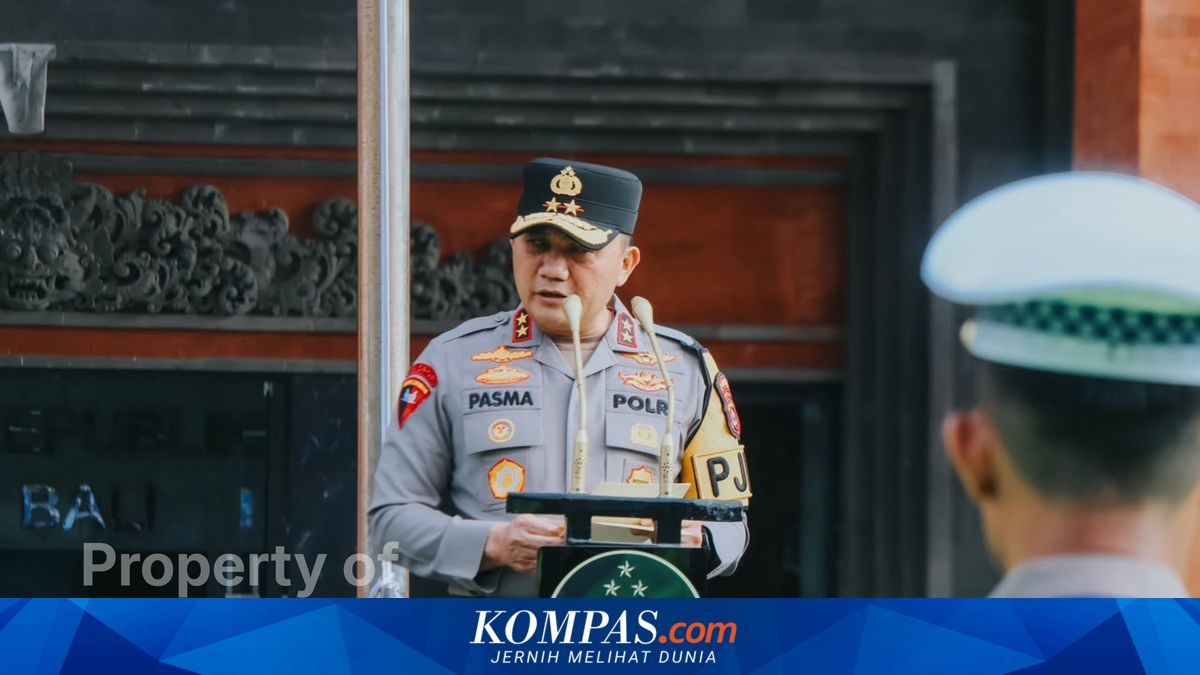

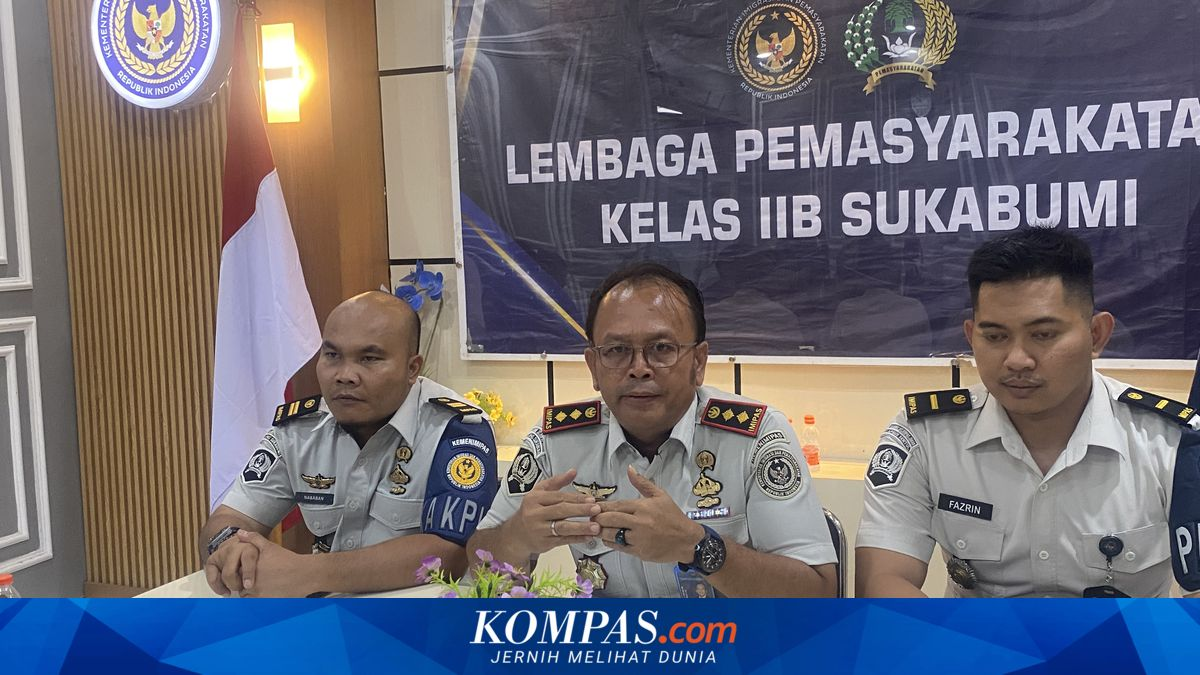

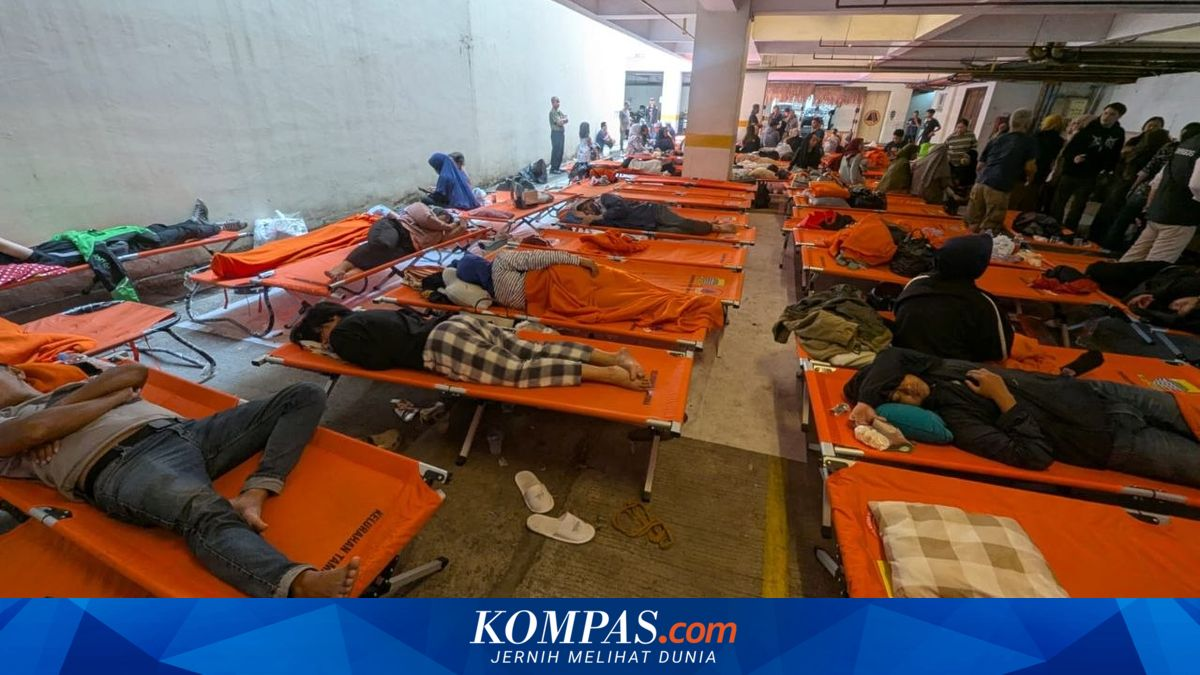

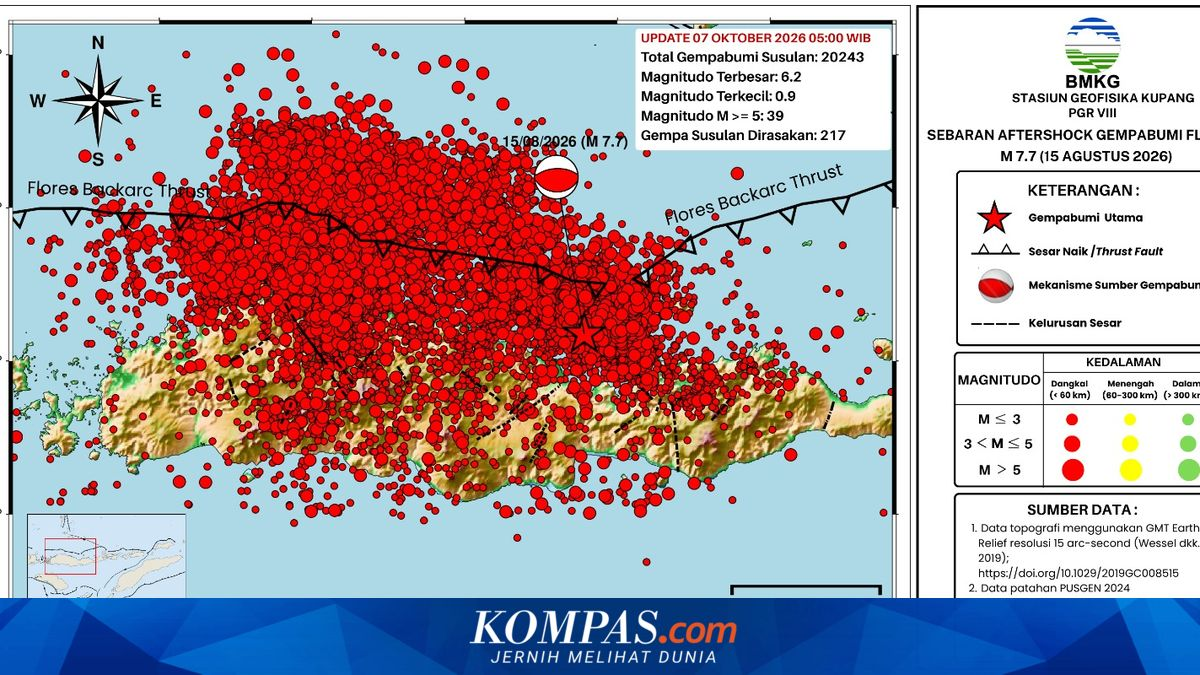

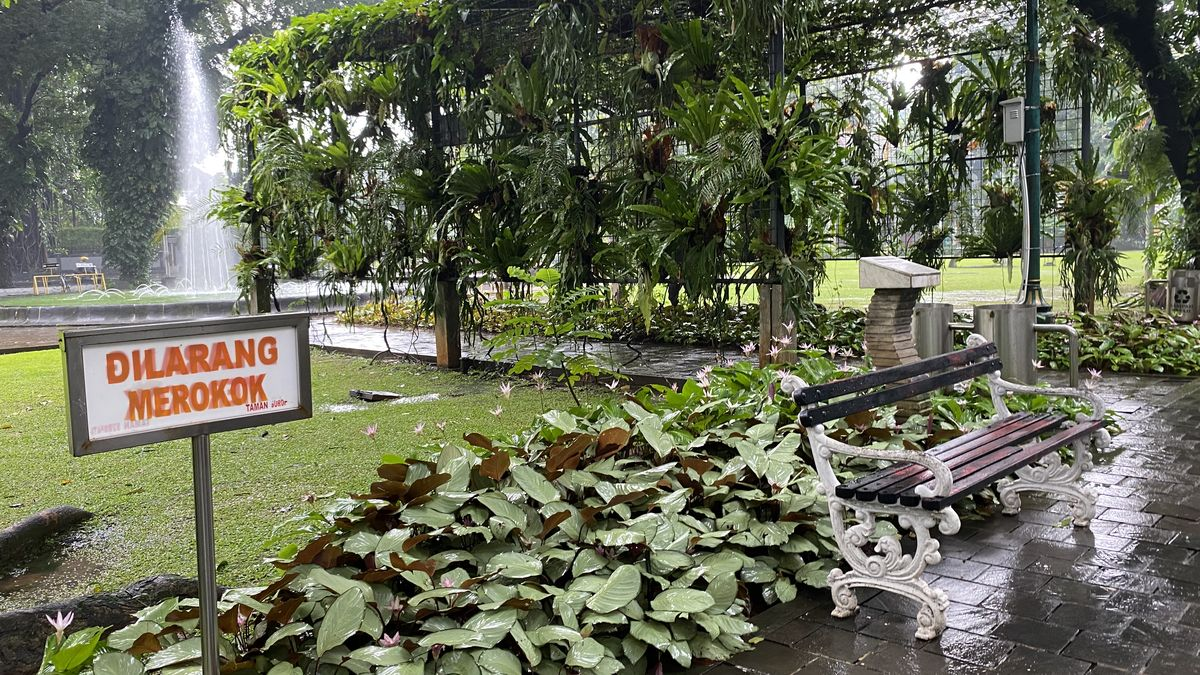

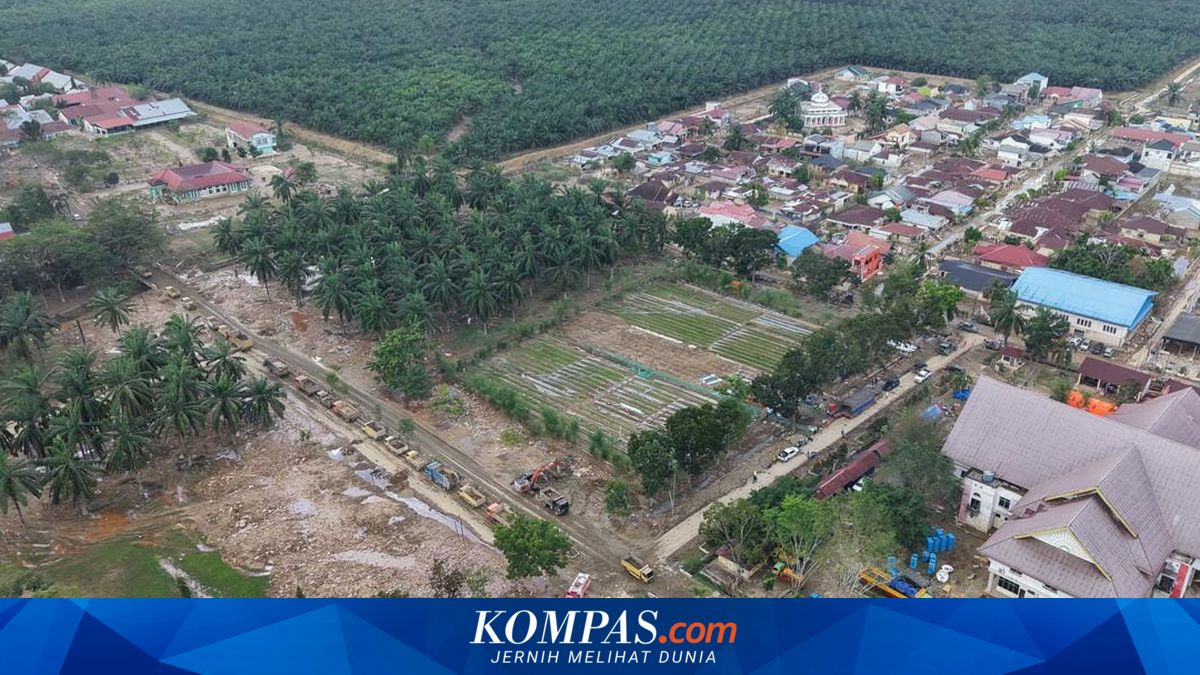

In [38]:
from IPython.display import Image as IPImage, display, HTML

manifest = {r["url"]: r for r in read_jsonl(MANIFEST)}
for label in ("true", "miscaptioned", "out-of-context"):
    rows = [p for p in locked if p["label"] == label][:2]
    display(HTML(f"<h4 style='margin:14px 0 6px'>{label}</h4>"))
    for p in rows:
        rec = manifest.get(p["image"], {})
        path = IMG_DIR / rec.get("file", "")
        display(HTML(f"<div style='font-size:13px;color:#888'>fold {p['fold']} · "
                     f"{p['category']} · {p['source'].split('/')[-1][:60]}</div>"
                     f"<div style='margin:4px 0 10px;max-width:520px'>{p['caption']}</div>"))
        if path.exists():
            display(IPImage(filename=str(path), width=420))
        else:
            display(HTML("<i>gambar tidak tersedia</i>"))